# Generative-AI task exposure by occupation group

Employment-weighted LLM task exposure (Eloundou, Manning, Mishkin & Rock 2024) for internet-era digital occupations, pre-1995 physical-economy occupations, and pre-1995 office and professional occupations, using OEWS May 2025 employment. Method and sensitivity: `analysis/ai_exposure/METHOD.md`.

**Datasets:** —

This notebook reads the latest vintage each time it runs; re-run after a new release to update every table and chart.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from labobs.load import load, vintage, curated, raw_payload
from labobs.nb import select, pivot, latest, plot_lines, plot_bars, to_annual, FOCUS, FOCUS_NAMES
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
from labobs import REPO_ROOT
A = REPO_ROOT / "analysis" / "ai_exposure" / "outputs"
g = pd.read_csv(A / "G_exposure_by_group.csv")
g

,group,group_name,n_occ,employment,emp_share_of_total_pct,wmean_human_alpha,wmean_human_beta,wmean_human_zeta,wmean_gpt4_alpha,wmean_gpt4_beta,...,pct_emp_ge50_human_zeta,pct_emp_ge50_gpt4_alpha,pct_emp_ge50_gpt4_beta,pct_emp_ge50_gpt4_zeta,pct_emp_gt50_human_beta,pct_emp_ge10_human_beta,unweighted_mean_human_beta,pct_emp_gt50_gpt4_beta,pct_emp_ge10_gpt4_beta,unweighted_mean_gpt4_beta
0,A,(a) Internet-era digital/information,30,10108910,6.50,0.29,0.58,0.87,0.37,0.66,...,98.59,28.33,99.35,99.35,77.83,100.00,0.54,97.39,100.00,0.69
1,B,(b) Pre-1995 physical economy,508,89137390,57.32,0.08,0.18,0.28,0.09,0.21,...,16.30,0.08,3.99,27.70,1.45,69.37,0.17,3.63,69.78,0.21
2,C,(c) Pre-1995 office/professional,113,33493240,21.54,0.23,0.49,0.75,0.21,0.55,...,93.67,8.01,63.87,97.91,40.74,100.00,0.49,58.22,100.00,0.55
3,D,"(d) Other pre-1995 (sales, science, social ser...",179,22742300,14.63,0.26,0.43,0.59,0.15,0.41,...,52.12,0.75,30.14,77.94,29.05,97.55,0.44,28.82,99.90,0.46
4,a1_tech,subgroup,18,5837390,3.75,0.23,0.54,0.86,0.53,0.73,...,98.69,45.89,100.00,100.00,69.13,100.00,0.57,100.00,100.00,0.75
5,a2_digital_mkt_media,subgroup,5,1188490,0.76,0.11,0.52,0.93,0.06,0.53,...,100.00,0.00,100.00,100.00,79.52,100.00,0.51,83.35,100.00,0.56
6,a3_digital_clerical,subgroup,5,428850,0.28,0.21,0.48,0.76,0.43,0.66,...,84.70,29.63,84.70,84.70,54.29,100.00,0.46,84.70,100.00,0.64
7,a4_contact_centre,subgroup,2,2654180,1.71,0.54,0.70,0.86,0.15,0.57,...,100.00,2.20,100.00,100.00,100.00,100.00,0.62,100.00,100.00,0.69
8,b1_physical_major,subgroup,447,77877240,50.08,0.07,0.15,0.24,0.09,0.18,...,9.98,0.09,1.81,20.29,0.14,64.94,0.14,1.80,65.41,0.18
9,b2_physical_white_collar,subgroup,61,11260150,7.24,0.17,0.37,0.57,0.10,0.39,...,59.97,0.00,19.12,78.91,10.55,100.00,0.40,16.26,100.00,0.44


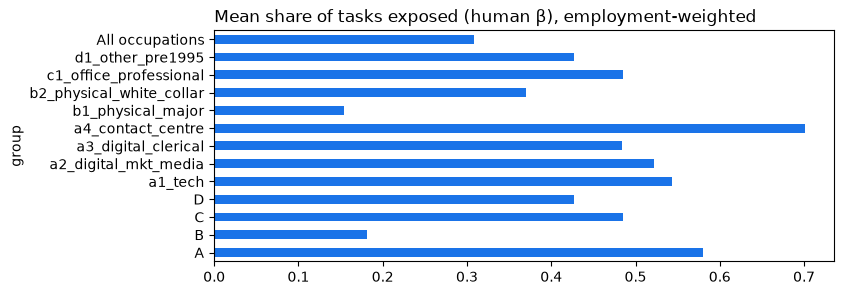

In [3]:
col = [c for c in g.columns if "human_beta" in c and "mean" in c] or [c for c in g.columns if "human_beta" in c]
ax = g.set_index(g.columns[0])[col[0]].plot.barh(figsize=(8, 3), color="#1a73e8")
ax.set_title("Mean share of tasks exposed (human β), employment-weighted", loc="left");

In [4]:
mg = pd.read_csv(A / "G_exposure_by_major_group.csv")
mg.sort_values(mg.columns[-1], ascending=False).head(25)

,major,major_name,n_occ,employment,emp_share_of_total_pct,wmean_human_alpha,wmean_human_beta,wmean_human_zeta,wmean_gpt4_alpha,wmean_gpt4_beta,...,pct_emp_ge50_human_zeta,pct_emp_ge50_gpt4_alpha,pct_emp_ge50_gpt4_beta,pct_emp_ge50_gpt4_zeta,pct_emp_gt50_human_beta,pct_emp_ge10_human_beta,unweighted_mean_human_beta,pct_emp_gt50_gpt4_beta,pct_emp_ge10_gpt4_beta,unweighted_mean_gpt4_beta
0,15,Computer & mathematical,21,5260120,3.38,0.22,0.55,0.88,0.57,0.75,...,100.00,49.57,100.00,100.00,67.20,100.00,0.60,99.49,100.00,0.76
1,43,Office & administrative support,54,17753420,11.42,0.31,0.53,0.74,0.33,0.60,...,88.26,15.82,87.05,96.06,56.87,100.00,0.49,80.97,100.00,0.62
2,13,Business & financial operations,32,10537240,6.78,0.22,0.52,0.81,0.13,0.54,...,99.88,0.00,80.95,100.00,62.72,100.00,0.52,75.54,100.00,0.52
4,23,Legal,8,1305620,0.84,0.12,0.47,0.81,0.08,0.47,...,98.16,0.00,40.37,100.00,7.30,100.00,0.43,38.41,100.00,0.50
5,17,Architecture & engineering,36,2617130,1.68,0.20,0.45,0.69,0.17,0.52,...,90.87,2.93,66.52,97.71,35.80,100.00,0.42,62.78,100.00,0.49
8,27,"Arts, design, entertainment, sports & media",41,2046270,1.32,0.23,0.42,0.62,0.17,0.48,...,61.35,7.09,50.81,92.85,29.98,98.43,0.36,35.05,98.87,0.47
7,11,Management,37,11119550,7.15,0.16,0.43,0.70,0.03,0.47,...,99.94,0.00,14.99,100.00,11.36,100.00,0.45,11.00,100.00,0.47
3,19,"Life, physical & social science",48,1473280,0.95,0.28,0.48,0.68,0.12,0.45,...,80.70,1.39,35.95,98.57,44.88,100.00,0.49,35.36,100.00,0.46
6,41,Sales & related,22,13424280,8.63,0.29,0.45,0.61,0.15,0.41,...,45.94,0.44,32.64,75.60,33.53,100.00,0.49,32.29,100.00,0.45
10,25,Educational instruction & library,64,9100600,5.85,0.17,0.34,0.51,0.14,0.36,...,45.17,0.00,11.17,68.66,8.39,94.23,0.42,10.14,100.00,0.44


In [5]:
pd.read_csv(A / "G_sensitivity.csv")

,variant,A_emp_m,A_wmean_human_alpha,A_wmean_human_beta,A_wmean_human_zeta,A_wmean_gpt4_beta,A_pct_ge50_human_beta,A_pct_ge50_human_zeta,B_emp_m,B_wmean_human_alpha,...,B_pct_ge50_human_beta,B_pct_ge50_human_zeta,rest_emp_m,rest_wmean_human_alpha,rest_wmean_human_beta,rest_wmean_human_zeta,rest_wmean_gpt4_beta,rest_pct_ge50_human_beta,rest_pct_ge50_human_zeta,ratio_A_over_B_human_beta
0,baseline (A = a1+a2+a3+a4),10.11,0.29,0.58,0.87,0.66,78.20,98.59,89.14,0.08,...,1.50,16.30,56.24,0.24,0.46,0.68,0.50,44.08,76.86,3.20
1,A = a1 tech only,5.84,0.23,0.54,0.86,0.73,69.77,98.69,89.14,0.08,...,1.50,16.30,60.51,0.25,0.47,0.70,0.50,47.30,78.39,3.00
2,"A = a1+a2 (no clerical, no contact centre)",7.03,0.21,0.54,0.87,0.69,71.42,98.91,89.14,0.08,...,1.50,16.30,59.32,0.25,0.47,0.69,0.50,46.65,77.96,2.98
3,A excludes customer service reps (43-4051),7.51,0.21,0.54,0.87,0.69,70.66,98.11,89.14,0.08,...,1.50,16.30,58.83,0.25,0.47,0.69,0.50,46.54,77.89,2.96
4,A excludes contact centre (a4),7.45,0.21,0.54,0.87,0.69,70.44,98.09,89.14,0.08,...,1.50,16.30,58.89,0.25,0.47,0.69,0.50,46.60,77.91,2.96
5,A + all office & admin support (43),25.14,0.28,0.53,0.78,0.63,71.75,91.14,89.14,0.08,...,1.50,16.30,41.21,0.23,0.45,0.67,0.46,35.57,73.49,2.92
6,A + all office/admin (43) + sales (41),38.50,0.28,0.50,0.72,0.55,58.38,75.37,89.14,0.08,...,1.50,16.30,27.84,0.20,0.45,0.70,0.48,36.68,86.82,2.76
7,B = physical major groups only (b1),10.11,0.29,0.58,0.87,0.66,78.20,98.59,77.88,0.07,...,0.14,9.98,67.50,0.23,0.45,0.66,0.48,38.55,74.05,3.76
8,B excludes healthcare practitioners (29),10.11,0.29,0.58,0.87,0.66,78.20,98.59,79.55,0.07,...,1.61,10.57,65.83,0.22,0.44,0.65,0.47,37.74,74.96,3.46
9,exclude imputed exposure rows,10.11,0.29,0.58,0.87,0.66,78.20,98.59,88.37,0.08,...,1.52,16.42,57.00,0.24,0.46,0.68,0.49,43.48,75.86,3.19


To refresh after a new OEWS release: update `analysis/ai_exposure/inputs/` and run `python analysis/ai_exposure/exposure.py`.

## Curator notes

_Written by the curator after each new vintage: what changed, which revisions matter, and what to watch. See `DATA_CHANGELOG.md` for the full log._